<a href="https://colab.research.google.com/github/kangtayie/Machine-Learning_class/blob/main/MNIST_classification_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
# 1. 라이브러리 임포트 및 데이터 로드
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# sklearn 내장 손글씨 숫자 데이터 (8x8 크기, 1797장)
digits = datasets.load_digits()

이미지 shape: (1797, 8, 8)
클래스별 개수: [178 182 177 183 181 182 181 179 174 180]


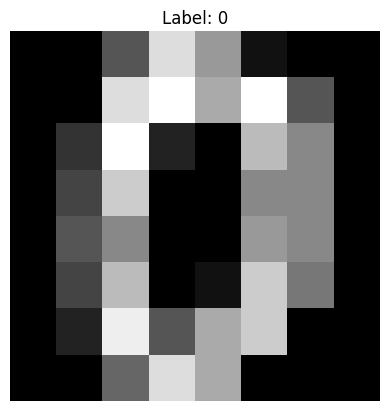

In [12]:
# 2. 데이터 확인

# 이미지 데이터 형태와 클래스별 개수 확인
print("이미지 shape:", digits.images.shape)
print("클래스별 개수:", np.bincount(digits.target))

# 첫 번째 이미지 시각화
plt.imshow(digits.images[0], cmap="gray")
plt.title(f"Label: {digits.target[0]}")
plt.axis("off")
plt.show()

In [13]:
# 3. 전처리

# [MLP와 다른 점] 이미지를 64칸 벡터로 펼치지 않고 8x8 모양을 그대로 유지
# CNN은 (높이, 너비, 채널) 형태의 입력이 필요하므로 채널 축(흑백=1)을 추가
X = digits.images.reshape(-1, 8, 8, 1)   # (1797, 8, 8, 1)
y = digits.target

# 학습/테스트 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 정규화: 픽셀값 범위가 0~16이므로 16으로 나눠 0~1로 맞춤
X_train = X_train / 16.0
X_test = X_test / 16.0

# 정답 라벨을 원-핫 인코딩
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=10)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (1437, 8, 8, 1) X_test: (360, 8, 8, 1)


In [4]:
# 4. CNN 모델 구조

model = tf.keras.Sequential([
    # 입력: 8x8 흑백 이미지
    layers.Input(shape=(8, 8, 1)),

    # [합성곱층 1] 3x3 필터 32개로 선·모서리 같은 기본 특징 추출
    # padding="same": 출력 크기를 입력과 같게 유지
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    # [풀링층 1: 2X2 MaxPooling]
    layers.MaxPooling2D((2, 2)),

    # [합성곱층 2] 필터 64개로 곡선·형태 같은 더 복잡한 특징 추출
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # 2차원 특징맵을 1줄로 펼쳐 Dense층에 전달
    layers.Flatten(),

    # 이전 MLP처럼 Dense층으로 최종 분류
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [14]:
# 5. 컴파일

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [15]:
# 6. 모델 구조 출력

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,914 (140.29 KB)

 Trainable params: 35,914 (140.29 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# 7. 학습

history = model.fit(
    X_train, y_train_oh,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9965 - loss: 0.0144 - val_accuracy: 0.9688 - val_loss: 0.0674
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9974 - loss: 0.0144 - val_accuracy: 0.9688 - val_loss: 0.1087
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9869 - loss: 0.0396 - val_accuracy: 0.9826 - val_loss: 0.0451
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0048 - val_accuracy: 0.9826 - val_loss: 0.0538
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 0.9826 - val_loss: 0.0531
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 0.9826 - val_loss: 0.0493
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 9.7951e-04 - val_accuracy: 0.9826 - val_loss: 0.0505
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 8.8319e-04 - val_accuracy: 0.9792 

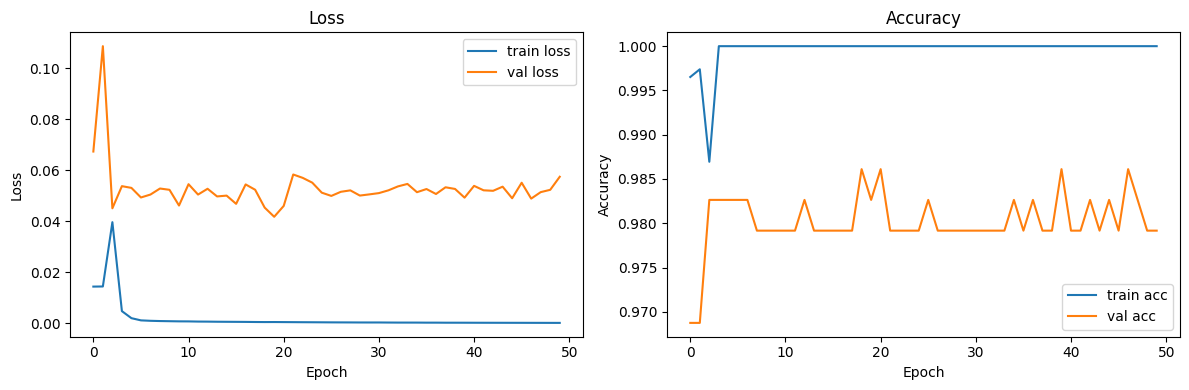

In [17]:
# 8. 학습 곡선 시각화

plt.figure(figsize=(12, 4))

# 손실 변화
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss")
plt.legend()

# 정확도 변화
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

Test loss: 0.0859
Test accuracy: 0.9833
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.95      0.97      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      0.97      0.99        37
           4       0.97      1.00      0.99        36
           5       0.97      1.00      0.99        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.97      0.94      0.96        35
           9       1.00      1.00      1.00        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



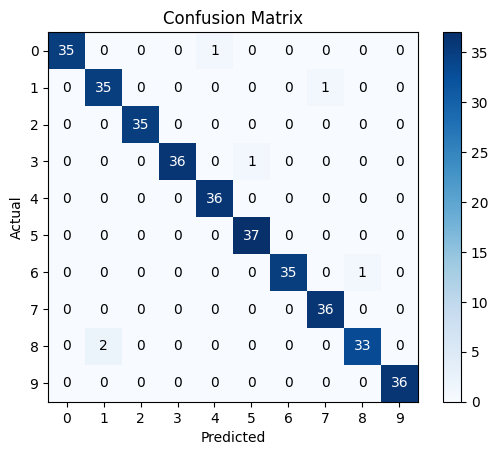

In [18]:
# 9. 테스트셋 평가

# 한 번도 보지 않은 테스트 데이터로 최종 성능 평가
test_loss, test_acc = model.evaluate(X_test, y_test_oh, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

# 예측: 10개 확률 중 가장 큰 값의 위치 = 예측한 숫자
y_pred = np.argmax(model.predict(X_test), axis=1)

# 숫자별 정밀도/재현율/F1
print(classification_report(y_test, y_pred))

# 혼동행렬: 어떤 숫자를 어떤 숫자로 헷갈렸는지
cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.xticks(range(10)); plt.yticks(range(10))
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.show()

틀린 개수: 6 / 360


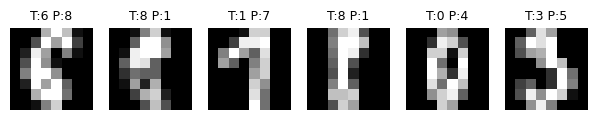

In [19]:
# 10. 틀린 예측 확인

# 모델이 틀린 이미지만 골라서 보기
wrong = np.where(y_pred != y_test)[0]
print(f"틀린 개수: {len(wrong)} / {len(y_test)}")

plt.figure(figsize=(10, 3))
for k, idx in enumerate(wrong[:8]):   # 최대 8개만 표시
    plt.subplot(1, 8, k + 1)
    plt.imshow(X_test[idx].reshape(8, 8), cmap="gray")
    plt.title(f"T:{y_test[idx]} P:{y_pred[idx]}", fontsize=9)   # T=정답, P=예측
    plt.axis("off")
plt.show()